# Multimodal Deception Detection: Environment Setup

First, you must install OpenFace to extract facial Action Units and head pose data.
Follow the steps from [here](https://github.com/TadasBaltrusaitis/OpenFace/wiki#installation).
Afterwards, in the configuration section you must pinpoint to openface build binary feature extractor

# Imports and configuration

In [1]:
import sys
import os
current_dir = os.getcwd()
project_root = os.path.abspath(os.path.join(current_dir, '..'))
if project_root not in sys.path:
    sys.path.append(project_root)
os.environ["LIBGL_ALWAYS_SOFTWARE"] = "1"
import glob
import tempfile
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from src.extractors.visual.visual_feature_extractor import VisualFeatureExtractor
from huggingface_hub import snapshot_download
from scenedetect import detect, ContentDetector
from src.common.constants import OPENFACE_BIN
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

# Hardware Configuration
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Directory & Binary Path Configurations
DATA_DIR = os.path.expanduser("../data/DOLO")
HF_DATASET_NAME = "dandyidk/Multi-Modal-Lie-Detection"
print(f"CUDA Available: {torch.cuda.is_available()} | Device: {DEVICE}")
print(f"Loading Hugging Face Dataset: {HF_DATASET_NAME}")
print(f"OpenFace Executable: {OPENFACE_BIN}")

/bin/bash: warning: setlocale: LC_ALL: cannot change locale (en_US.UTF-8)


CUDA Available: True | Device: cuda
Loading Hugging Face Dataset: dandyidk/Multi-Modal-Lie-Detection
OpenFace Executable: /home/dandy/OpenFace/build/bin/FeatureExtraction


# Remote Dataset Inspection

In [2]:
from huggingface_hub import HfApi

api = HfApi()

files = api.list_repo_files(
    repo_id="dandyidk/Multimodal",
    repo_type="dataset",
)

# Use a tuple of folder strings to check multiple paths
target_folders = ("DOLOS/Data/", "Real-life_Deception_Detection_2016/Clips") 

filtered_files = []
for filename in files:
    if filename.startswith(target_folders):
        filtered_files.append(filename)
        # pass 

print(f"Found {len(filtered_files)} files across the target folders.")

Found 1558 files across the target folders.


### Dataset Download and Metadata Extraction
Download the dataset using `snapshot_download`. Once downloaded, recursively locate all `.mp4` files and use OpenCV (`cv2`) to extract baseline video metadata, such as frame count, FPS, and total duration in seconds. This information is saved into a Pandas DataFrame (`meta_df`) for downstream processing.

In [3]:
os.makedirs(DATA_DIR, exist_ok=True)
repo_dir = snapshot_download(
    repo_id=HF_DATASET_NAME,
    repo_type="dataset",
    local_dir=DATA_DIR
)

# Locate all local MP4 files recursively
video_paths = sorted(glob.glob(os.path.join(DATA_DIR, "**", "*.mp4"), recursive=True))

video_stats = []

for idx, video_path in enumerate(video_paths):
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print(f"Warning: Failed to open video at {video_path}")
        continue

    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    duration = frame_count / fps if fps and fps > 0 else 0.0

    video_stats.append({
        "sample_index": idx,
        "filename": os.path.basename(video_path),
        "path": video_path,  # Physical disk path for OpenFace
        "frame_count": frame_count,
        "fps": round(float(fps), 2),
        "duration_sec": round(float(duration), 2),
    })
    cap.release()

meta_df = pd.DataFrame(video_stats)
print(f"Successfully loaded and verified {len(meta_df)} video files.")
meta_df.head()

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 1934 files:   0%|          | 0/1934 [00:00<?, ?it/s]

Successfully loaded and verified 1557 video files.


,sample_index,filename,path,frame_count,fps,duration_sec
0,0,AN_WILTY_EP15_lie10.mp4,../data/DOLO/DOLOS/Data/AN_WILTY_EP15_lie10.mp4,75,25.0,3.0
1,1,AN_WILTY_EP15_lie11.mp4,../data/DOLO/DOLOS/Data/AN_WILTY_EP15_lie11.mp4,75,25.0,3.0
2,2,AN_WILTY_EP15_lie12.mp4,../data/DOLO/DOLOS/Data/AN_WILTY_EP15_lie12.mp4,100,25.0,4.0
3,3,AN_WILTY_EP15_lie13.mp4,../data/DOLO/DOLOS/Data/AN_WILTY_EP15_lie13.mp4,100,25.0,4.0
4,4,AN_WILTY_EP15_lie14.mp4,../data/DOLO/DOLOS/Data/AN_WILTY_EP15_lie14.mp4,150,25.0,6.0


## EDA: el l3b kolo :D
this analysis evaluates a sliding window chunking approach, cutting long videos into multiple smaller, fixed-length segments (e.g., 8 seconds) to maintain a uniform tensor shape without excessive padding.

/tmp/ipykernel_14379/3081501204.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=meta_df, x='projected_chunks', ax=axes[1], palette="magma")


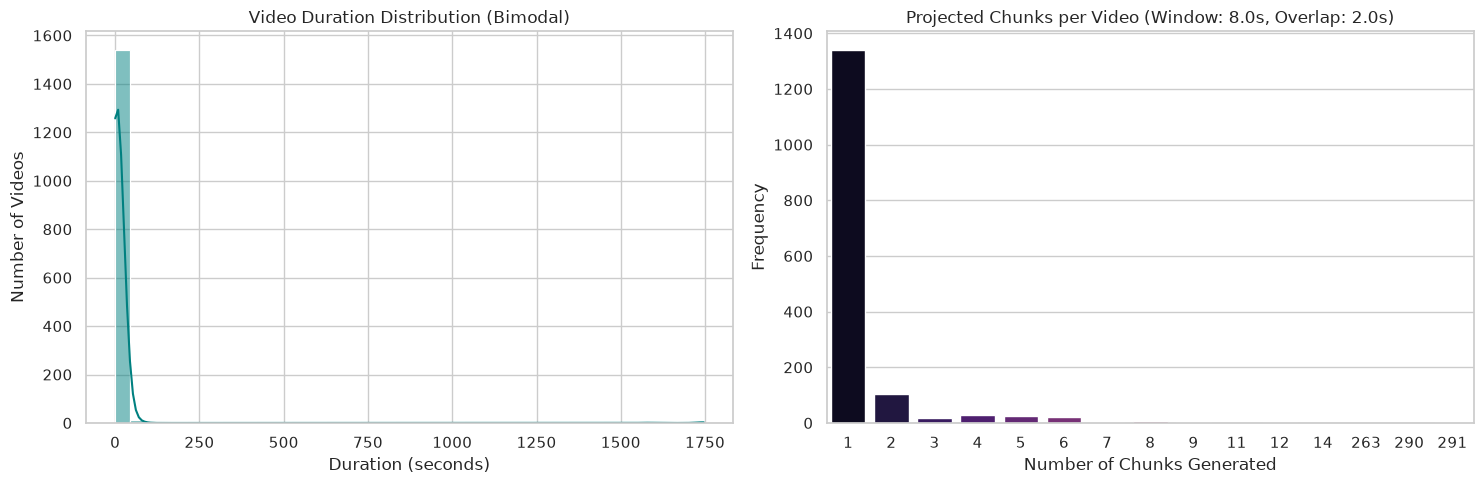

--- Chunking Strategy Recommendations ---
Target FPS              : 25
Sequence Length (T)     : 200 frames (8.0 seconds)
Original Video Count    : 1557
Projected Dataset Size  : 3253 chunked sequences

By chunking, the 30-second clips act as data augmentation (providing multiple samples), 
and you avoid VRAM exhaustion during the cross-modal attention and GRU operations.


In [4]:
# Ensure meta_df exists and has 'duration_sec' and 'fps' columns populated from earlier steps
if not meta_df.empty:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # Plot 1: The Bimodal Distribution
    sns.histplot(meta_df["duration_sec"], bins=40, kde=True, ax=axes[0], color="teal")
    axes[0].set_title("Video Duration Distribution (Bimodal)")
    axes[0].set_xlabel("Duration (seconds)")
    axes[0].set_ylabel("Number of Videos")
    
    # Chunking Parameters
    target_fps = int(meta_df["fps"].mode()[0])
    chunk_length_sec = 8.0  # Set to match the peak of the shorter dataset
    overlap_sec = 2.0       # Overlap to preserve context across boundaries
    
    chunk_frames = int(chunk_length_sec * target_fps)
    
    # Calculate how many chunks each video will produce
    def calculate_chunks(duration):
        if duration <= chunk_length_sec:
            return 1
        else:
            # Formula for sliding window chunks
            return int(np.ceil((duration - chunk_length_sec) / (chunk_length_sec - overlap_sec))) + 1

    meta_df['projected_chunks'] = meta_df['duration_sec'].apply(calculate_chunks)
    
    # Plot 2: Projected Dataset Size After Chunking
    sns.countplot(data=meta_df, x='projected_chunks', ax=axes[1], palette="magma")
    axes[1].set_title(f"Projected Chunks per Video (Window: {chunk_length_sec}s, Overlap: {overlap_sec}s)")
    axes[1].set_xlabel("Number of Chunks Generated")
    axes[1].set_ylabel("Frequency")

    plt.tight_layout()
    plt.show()

    total_original = len(meta_df)
    total_chunks = meta_df['projected_chunks'].sum()
    
    print("--- Chunking Strategy Recommendations ---")
    print(f"Target FPS              : {target_fps}")
    print(f"Sequence Length (T)     : {chunk_frames} frames ({chunk_length_sec} seconds)")
    print(f"Original Video Count    : {total_original}")
    print(f"Projected Dataset Size  : {total_chunks} chunked sequences")
    print("\nBy chunking, the 30-second clips act as data augmentation (providing multiple samples), ")
    print("and you avoid VRAM exhaustion during the cross-modal attention and GRU operations.")

### Deception Class Balance

/tmp/ipykernel_14379/249587841.py:15: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.countplot(data=meta_df, x='label', hue='label', palette=['#E74C3C', '#2ECC71', '#95A5A6'], legend=False)


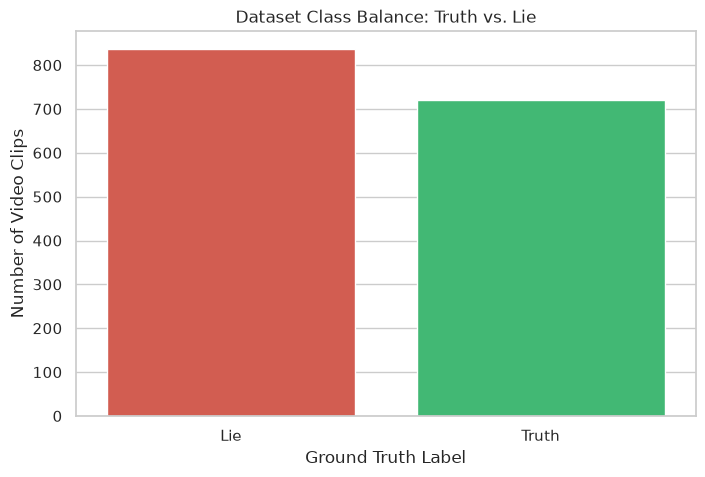

Class Distribution:
label
Lie      836
Truth    721
Name: count, dtype: int64


In [ ]:
if not meta_df.empty:
    def extract_label(filename):
        fname_lower = filename.lower()
        if 'lie' in fname_lower or 'deception' in fname_lower:
            return 'Lie'
        elif 'truth' in fname_lower or 'true' in fname_lower:
            return 'Truth'
        else:
            print("stuff")
            return 'Unknown'
            
    meta_df['label'] = meta_df['filename'].apply(extract_label)
    
    plt.figure(figsize=(8, 5))
    sns.countplot(data=meta_df, x='label', hue='label', palette=['#E74C3C', '#2ECC71', '#95A5A6'], legend=False)
    plt.title('Dataset Class Balance: Truth vs. Lie')
    plt.xlabel('Ground Truth Label')
    plt.ylabel('Number of Video Clips')
    plt.show()
    
    print("Class Distribution:")
    print(meta_df['label'].value_counts())

## OpenFace Quality Analysis and Feature Extraction
Here, we initialize the `VisualFeatureExtractor` to run OpenFace on a sample of the videos. The block extracts the facial features, evaluates tracking confidence, and calculates the Root Mean Square (RMS) jitter for spatial translation (Tx, Ty, Tz). High dropout rates or excessive jitter indicate poor tracking stability, which can negatively impact Action Unit recognition.

In [6]:
JITTER_THRESH = 5.0
CONF_THRESH = 0.75


extractor = VisualFeatureExtractor(openface_bin_path=OPENFACE_BIN, device=DEVICE)
results = []

# Test up to 10 randomly selected videos
for _, r in meta_df.sample(min(10, len(meta_df)), random_state=42).iterrows():
    path, name = r["path"], os.path.basename(r["path"])

    # Detect scene boundaries; use the entire video if no cuts are detected
    scenes = [(s.get_frames() + 1, e.get_frames())
              for s, e in detect(path, ContentDetector())] or [(1, float("inf"))]

    # Extract facial landmarks, head pose, gaze, and tracking confidence
    with tempfile.TemporaryDirectory() as tmp:
        df = extractor.run_openface(path, tmp, landmarks=True)
    if df is None or df.empty:
        continue
    df.columns = df.columns.str.strip()

    for i, (start, end) in enumerate(scenes, 1):
        scene = df[df.frame.between(start, end)].copy()
        if scene.empty:
            continue

        # Exclude low-confidence frames from motion and gaze calculations
        valid = scene[scene.confidence >= CONF_THRESH]
        pos = ["pose_Tx", "pose_Ty", "pose_Tz"]
        rot = ["pose_Rx", "pose_Ry", "pose_Rz"]
        gaze = ["gaze_angle_x", "gaze_angle_y"]

        # Estimate frame-to-frame head translation jitter (consecutive frames only)
        diff = valid[pos].diff().where(valid.frame.diff().eq(1))
        jitter = np.sqrt(diff.pow(2).mean()).fillna(0).values

        # Calculate head rotation and gaze variability in degrees
        head_std = valid[rot].std().fillna(0).values * 180 / np.pi
        gaze_std = valid[gaze].std().fillna(0).values * 180 / np.pi
        dropout = (scene.confidence < CONF_THRESH).mean() * 100

        results.append({
            "video": f"{name}_scene_{i}", "dropout": dropout,
            **dict(zip(["j_tx", "j_ty", "j_tz"], jitter)),
            **dict(zip(["head_pitch_std", "head_yaw_std", "head_roll_std"], head_std)),
            **dict(zip(["gaze_x_std", "gaze_y_std"], gaze_std))
        })
        print(f"{name}_scene_{i} | Dropout: {dropout:.1f}% | Jitter: {jitter.round(2)}")

        # Play scenes with high jitter and overlay landmarks and gaze directions
        # Play original and debug videos side by side for high-jitter scenes
        if jitter.max() > JITTER_THRESH:
            cap = cv2.VideoCapture(path)
            cap.set(cv2.CAP_PROP_POS_FRAMES, start - 1)
            delay = int(1000 / (cap.get(cv2.CAP_PROP_FPS) or 30))
            x_cols, y_cols = [f"x_{j}" for j in range(68)], [f"y_{j}" for j in range(68)]

            while cap.isOpened():
                ret, original = cap.read()
                if not ret:
                    break

                idx = int(cap.get(cv2.CAP_PROP_POS_FRAMES))
                if idx > end:
                    break

                debug = original.copy()
                d = scene[scene.frame == idx]

                if not d.empty:
                    d = d.iloc[0]
                    color = (0, 255, 0) if d.confidence >= CONF_THRESH else (0, 0, 255)

                    # Draw facial landmarks
                    if all(c in scene.columns for c in x_cols + y_cols):
                        for x, y in zip(d[x_cols], d[y_cols]):
                            if pd.notna(x) and pd.notna(y):
                                cv2.circle(debug, (int(x), int(y)), 3, color, -1)

                    # Draw gaze vectors for confident detections
                    if d.confidence >= CONF_THRESH:
                        dx = int(100 * np.sin(d.gaze_angle_x))
                        dy = int(-100 * np.sin(d.gaze_angle_y))

                        for ids in [range(36, 42), range(42, 48)]:
                            eye = (int(d[[f"x_{j}" for j in ids]].mean()),
                                int(d[[f"y_{j}" for j in ids]].mean()))
                            cv2.arrowedLine(debug, eye, (eye[0] + dx, eye[1] + dy),
                                            (255, 255, 0), 2, tipLength=0.2)

                        cv2.putText(debug, f"Gaze X: {np.degrees(d.gaze_angle_x):+.1f} deg",
                                    (20, 110), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 0), 2)

                # Label both panes
                cv2.putText(original, "Original Video", (20, 35),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
                cv2.putText(debug, f"Debug | Scene {i} | q: skip", (20, 35),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2)

                # Resize both panes equally and display side by side
                h = min(original.shape[0], debug.shape[0])
                w = int(original.shape[1] * h / original.shape[0])
                original = cv2.resize(original, (w, h))
                debug = cv2.resize(debug, (w, h))
                cv2.imshow("Original vs Debug", cv2.hconcat([original, debug]))

                if cv2.waitKey(delay) & 0xFF == ord("q"):
                    break

            cap.release()
            cv2.destroyAllWindows()

# Summarize average jitter and gaze dispersion across processed scenes
if results:
    res = pd.DataFrame(results)
    print("\n--- Dataset Averages ---")
    print("Mean Jitter (Tx, Ty, Tz):",
          res[["j_tx", "j_ty", "j_tz"]].mean().round(2).values)
    print(f"Mean Gaze Dispersion: X={res.gaze_x_std.mean():.2f}° | "
          f"Y={res.gaze_y_std.mean():.2f}°")

/tmp/ipykernel_14379/474763318.py:13: DeprecationWarning: get_frames() is deprecated, use the `frame_num` property instead.
  scenes = [(s.get_frames() + 1, e.get_frames())


trial_lie_061.mp4_scene_1 | Dropout: 0.0% | Jitter: [0.76 0.55 1.99]
trial_lie_061.mp4_scene_2 | Dropout: 0.0% | Jitter: [2.55 1.65 7.85]


QFontDatabase: Cannot find font directory /home/dandy/.venv/lib/python3.12/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/dandy/.venv/lib/python3.12/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/dandy/.venv/lib/python3.12/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/dandy/.venv/lib/python3.12/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/dandy/.venv/lib/python3.12/site-packages/cv2

trial_lie_061.mp4_scene_3 | Dropout: 100.0% | Jitter: [0. 0. 0.]
AN_WILTY_EP22_lie5.mp4_scene_1 | Dropout: 0.0% | Jitter: [0.38 0.76 3.48]
BRI_WILTY_EP59_truth_19.mp4_scene_1 | Dropout: 0.0% | Jitter: [2.1  1.16 2.53]
BRI_WILTY_EP63_truth_3.mp4_scene_1 | Dropout: 0.0% | Jitter: [35.67  3.7  28.98]
YW_WILTY_EP55_truth8.mp4_scene_1 | Dropout: 0.0% | Jitter: [ 70.62  25.2  105.76]
trial_truth_014.mp4_scene_1 | Dropout: 0.0% | Jitter: [0.57 0.67 2.16]
AN_WILTY_EP17_lie9.mp4_scene_1 | Dropout: 8.0% | Jitter: [1.51 1.87 4.  ]
BRI_WILTY_EP61_truth_34.mp4_scene_1 | Dropout: 0.0% | Jitter: [1.67 0.81 3.16]
LS_WILTY_EP4_lie15.mp4_scene_1 | Dropout: 0.0% | Jitter: [2.08 1.86 5.4 ]
BRI_WILTY_EP59_truth_2.mp4_scene_1 | Dropout: 0.0% | Jitter: [ 90.31  29.84 134.06]

--- Dataset Averages ---
Mean Jitter (Tx, Ty, Tz): [17.35  5.67 24.95]
Mean Gaze Dispersion: X=4.12° | Y=2.33°


## Emotion Probability EDA
This section isolates the 7-class emotion probabilities generated by the custom extraction model. Because the emotion probabilities occupy the final 7 dimensions of the 58-dimensional visual tensor, the EDA focuses on isolating those indices, comparing their distributions against the deception labels, and verifying temporal stability across the T=90 window.

In [7]:
emotion_labels = ["Angry", "Disgust", "Fear", "Happy", "Neutral", "Sad", "Surprise"]

# ---------------------------------------------------------
# NOTE: Replace this mock data block with actual DataLoader 
# or loaded .pt files from the 'data/processed/' directory.
# ---------------------------------------------------------
B, T, D = 100, 90, 58  # 100 clips, 90 frames, 58 features
visual_feats = torch.rand(B, T, D) 
# Normalize the mock emotion columns (last 7 dims) to simulate softmax probabilities
visual_feats[:, :, -7:] = torch.softmax(visual_feats[:, :, -7:], dim=-1)
labels = torch.randint(0, 2, (B,)) # 0 = Truthful, 1 = Deceptive
# ---------------------------------------------------------

# Extract ONLY the emotion probabilities (the last 7 features)
# Shape becomes: (Batch, Time, 7)
emotion_probs = visual_feats[:, :, -7:].numpy()
labels_np = labels.numpy()

print(f"Extracted Emotion Tensor Shape: {emotion_probs.shape}")

Extracted Emotion Tensor Shape: (100, 90, 7)


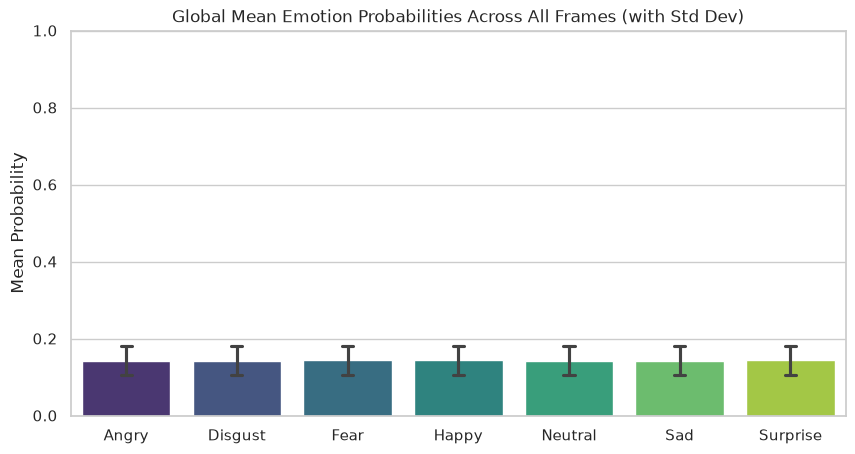

Global Prediction Entropy: 2.807 bits (Max possible: 2.807)


In [9]:
# Flatten across the Batch and Time dimensions to get a global view
flat_probs = emotion_probs.reshape(-1, len(emotion_labels))

# Convert to DataFrame for native Seaborn aggregation
df_global = pd.DataFrame(flat_probs, columns=emotion_labels)

plt.figure(figsize=(10, 5))
# Pass the dataframe directly; Seaborn calculates the mean and standard deviation
sns.barplot(
    data=df_global, 
    errorbar="sd", 
    palette="viridis",
    capsize=0.1
)
plt.title("Global Mean Emotion Probabilities Across All Frames (with Std Dev)")
plt.ylabel("Mean Probability")
plt.ylim(0, 1.0)
plt.show()

# Calculate global means manually just for the Entropy calculation
global_mean_probs = flat_probs.mean(axis=0)
entropy = -np.sum(global_mean_probs * np.log2(global_mean_probs + 1e-9))
print(f"Global Prediction Entropy: {entropy:.3f} bits (Max possible: 2.807)")

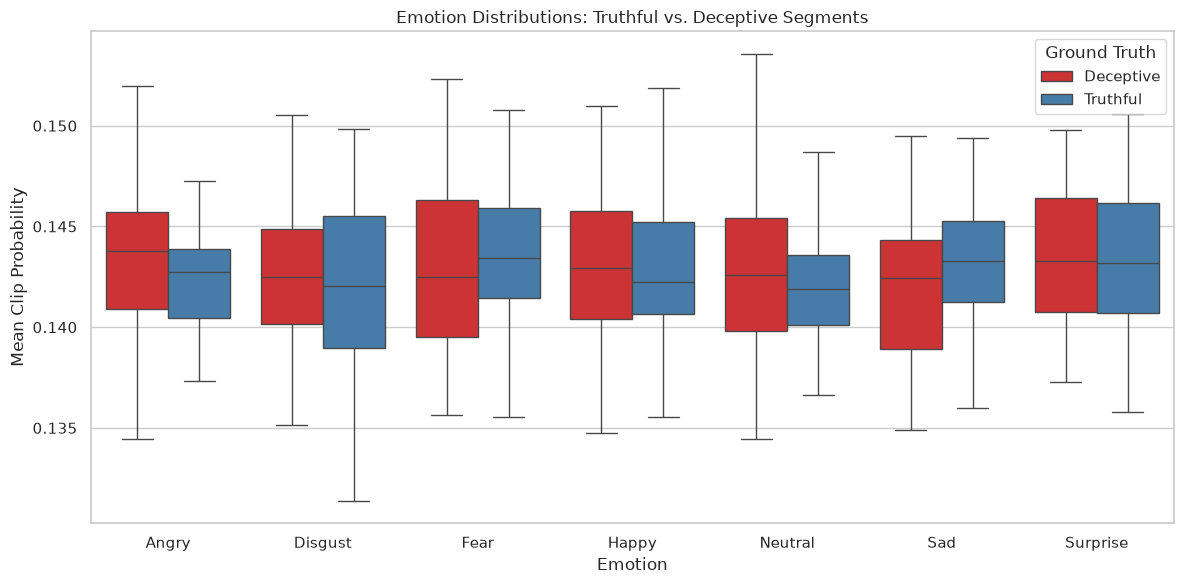

In [10]:
# Average the temporal dimension to get clip-level emotion summaries
clip_level_emotions = emotion_probs.mean(axis=1)

df_emotions = pd.DataFrame(clip_level_emotions, columns=emotion_labels)
df_emotions['Label'] = labels_np
df_emotions['Condition'] = df_emotions['Label'].map({0: 'Truthful', 1: 'Deceptive'})

df_melted = df_emotions.melt(
    id_vars=['Label', 'Condition'], 
    value_vars=emotion_labels, 
    var_name='Emotion', 
    value_name='Mean Clip Probability'
)

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df_melted, 
    x='Emotion', 
    y='Mean Clip Probability', 
    hue='Condition', 
    palette="Set1",
    showfliers=False
)
plt.title("Emotion Distributions: Truthful vs. Deceptive Segments")
plt.legend(title="Ground Truth")
plt.tight_layout()
plt.show()

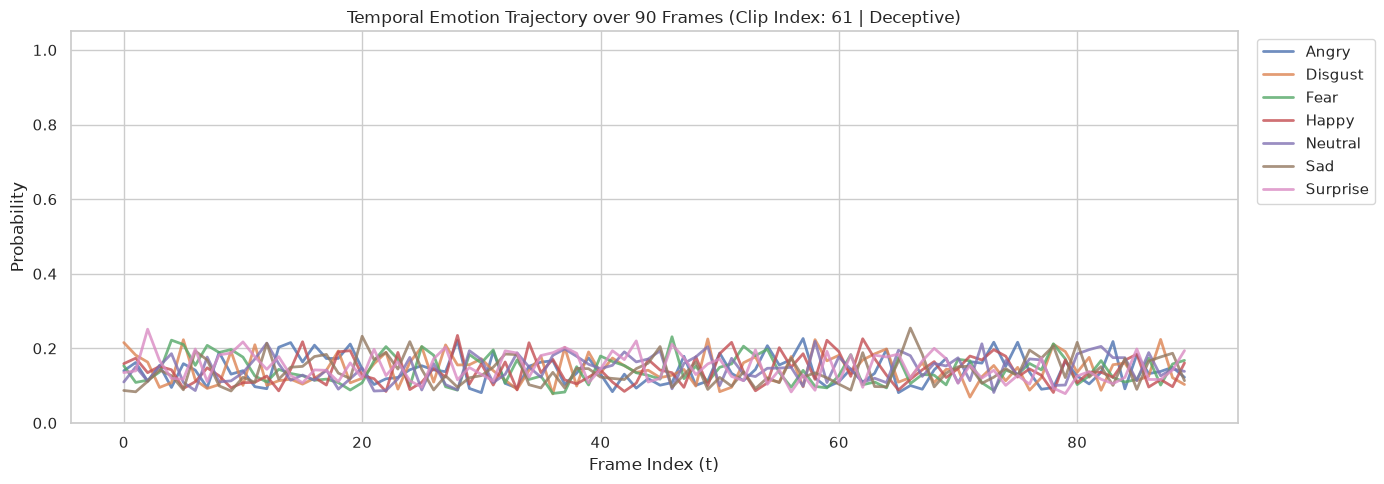

In [11]:
# Select a random clip to visualize its trajectory over time
sample_idx = np.random.randint(0, B)
sample_trajectory = emotion_probs[sample_idx] # Shape: (90, 7)
clip_label = "Deceptive" if labels_np[sample_idx] == 1 else "Truthful"

plt.figure(figsize=(14, 5))
for i, label in enumerate(emotion_labels):
    plt.plot(sample_trajectory[:, i], label=label, linewidth=2, alpha=0.8)

plt.title(f"Temporal Emotion Trajectory over {T} Frames (Clip Index: {sample_idx} | {clip_label})")
plt.xlabel("Frame Index (t)")
plt.ylabel("Probability")
plt.ylim(0, 1.05)

plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()